# Neural correlates of the cursor-shape clusters

The cursor-shape analysis split **correct** trials into four clusters by the shape of the cursor
trajectory (Section 7 of `cursor_shape_analysis.ipynb`). This notebook asks what the neural
population is doing during each of them:

1. **How does neural dimensionality evolve along a trial?** Participation ratio (PR) measured in
   overlapping windows that slide from trial start to trial end, separately per cluster.
2. **What does the average neural trajectory of each cluster look like in PC space?**

Both are run separately for three periods — **stable control**, the **first ~10 min of
intuitive-axis control** on remapping days, and **new-axis control** on remapping days. Washout is
discarded (it is always last in the session and confounded with time-on-task and motivation).

Tools live in `utilities/neural_cursor_utils.py` (`nc`), with dimensionality/trajectory primitives
from `utilities/neural_analysis_utils.py` (`na`) and the cursor clustering from
`utilities/cursor_analysis_utils.py` (`ca`). Analysis flow and all plotting stay open here.

---

## The fairness problem, and what is done about it

This is the crux of the first analysis, so it is worth being explicit.

**The clusters are largely duration clusters.** For `mouse_0403L` the median correct-trial duration
is ~6.5 s in cluster 1 and ~0.7 s in cluster 4 — a **9× range**, and the distributions barely
overlap (cluster 1's 10th percentile ≈ cluster 4's 90th percentile). So a naive PR comparison
between clusters would mostly be measuring trial length. PR is sensitive to four things that all
covary with duration:

| Confound | Why it inflates PR | Handled? |
|---|---|---|
| **Sample count** | PR is bounded by `n_samples − 1` and grows with it | **Removed exactly** — every estimate uses the same `n_trials × n_per_trial` |
| **Trial count** | more trials ⇒ more across-trial variance in the covariance | **Removed exactly** — matched `n_trials`, drawn at random |
| **Window width in real time** | neural state drifts, so a 2 s window explores more directions than a 0.2 s one | **Cannot be removed simultaneously with the next-to-last row** — see below |
| **Temporal autocorrelation** | calcium is smooth, so frames from a short window are more redundant | same |

The first two are removed by construction. The last two cannot be removed *at the same time as*
keeping "stage of the trial" meaningful, because holding the window's **fraction of the trial**
fixed and holding its **duration in seconds** fixed are mutually exclusive when trials differ in
length. Rather than pick one and hope, both are computed:

* **`relative` (primary, and what was suggested):** window width = a fixed fraction of each trial.
  "Position 3 of 9" means the same *stage* in every trial. Window seconds then differ between
  clusters, and the realised value is reported for every curve.
* **`absolute` (control):** window width = a fixed number of seconds. Drift and autocorrelation are
  now equalised, at the cost that the window covers a different fraction of a short vs a long trial.

**Agreement between the two is the evidence that a difference is not a duration artefact.** They
are not interchangeable and neither is "the right one" on its own.

Because duration-matching the clusters is not possible here (their duration distributions barely
overlap, so matching would discard nearly all the data), this two-mode bracketing is the available
substitute, and it is reported rather than hidden.

### Window width
The suggestion was ~1/5 of the trial. Checked empirically: at 1/5 the shortest cluster's window is
only ~4 frames (0.24 s), which forces a small frames-per-trial budget and produces a spurious
excursion at the first position. **1/3 is used by default** — it keeps ≥99 % of trials, allows 4
frames per trial instead of 2, and yields smoother curves. Section 5c shows the curves at 1/5, 1/3
and 1/2 so the choice is visible rather than asserted.

### Other choices
* **No binning.** The project normally bins neural data to 6 Hz, but the shortest cluster's trials
  are ~0.7 s, so a one-third window would be barely two bins. Data stay at the native **30 Hz**;
  z-scoring is per neuron over the whole session.
* **Absolute PR values are biased downward** by the matched sample budget and are only comparable
  *within* one setting of (`n_trials`, `n_per_trial`, mode, width). Compare shapes and ordering,
  never raw magnitudes across settings.
* **Clusters are recomputed, not imported.** The Section-7 pipeline (PCA → Ward) is deterministic,
  so the labels reproduce exactly; the notebook asserts the cluster sizes match.

## 1 · Setup and configuration

In [1]:
%matplotlib inline
import sys, warnings, time
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

REPO = Path.cwd(); sys.path.insert(0, str(REPO / "utilities"))
import importlib
import neural_analysis_utils as na; importlib.reload(na)
import cursor_analysis_utils as ca; importlib.reload(ca)
import neural_cursor_utils as nc; importlib.reload(nc)
import richfile as rfs; na.register_richfile_types(rfs)
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x

# ============================ CONFIG ============================
SR = 30
DATA_ROOT = Path(r"C:\Data\datasets\bmi_packets\bmi_packets")
OUT = REPO / "output" / "neural_cursor"; OUT.mkdir(parents=True, exist_ok=True)
SHAPE_OUT = REPO / "output" / "cursor_shape"     # cache written by cursor_shape_analysis.ipynb

MOUSE = "mouse_0403L"          # the only animal with stable + remapping phases
OUTCOME = "correct"            # Section 7's clusters are for correct trials
N_CLUSTERS = 4                 # must match N_CLUSTERS in cursor_shape_analysis.ipynb
EXPECTED_SIZES = [3520, 2263, 1164, 2188]   # asserted, so a config drift is caught loudly

# cursor-shape cache tag -- must match the cursor-shape notebook's window spec
PRE_SEC, POST_SEC, N_TRIAL_BINS = .25, .5, 40
CURSOR_COLUMN, CURSOR_TRANSFORM = "freqToOutput", "log2"
TAG = f"{CURSOR_COLUMN}_{CURSOR_TRANSFORM}_p{PRE_SEC}s{POST_SEC}_b{N_TRIAL_BINS}"
NORMALIZE_MODE, PCA_VAR_TARGET = "none", 0.95

INTUITIVE_MAX_MIN = 10.0       # "first ~10 minutes" of intuitive-axis control on remapping days

# --- analysis 1: PR along the trial ---
N_POSITIONS = 9                # overlapping window positions from trial start to trial end
WIDTH_FRAC = 1/3               # relative mode: window = this fraction of each trial
WIDTH_SEC = 0.4                # absolute mode: fixed window duration
N_PER_TRIAL = 4                # frames drawn per trial (matched everywhere)
N_BOOT = 25
WIDTH_SCAN = [0.2, 1/3, 0.5]   # sensitivity check

# --- 4d: cross-experiment control at the project's standard binning ---
BIN_FRAMES_CTRL = 5            # 5 frames @30 Hz -> 6 Hz, as used in the other neural notebooks
N_POSITIONS_CTRL = 3           # early / middle / late thirds of the trial
WIDTH_FRAC_CTRL = 1/3          # so the three windows tile the trial
N_PER_TRIAL_CTRL = 2           # the most cluster 4 can give at 6 Hz (its windows are ~2 bins)
MIN_BINS_CTRL = 2

# --- analysis 2: mean neural trajectory ---
N_PC = 6
N_WARP = 40                    # points per warped trajectory
PCA_MAX_FRAMES_PER_GROUP = 20000

USE_CACHE = True
SEED = 0
PERIODS = nc.PERIODS
PERIOD_LABEL = {"stable": "stable control",
                "remap_intuitive": f"remap: intuitive axis (first {INTUITIVE_MAX_MIN:.0f} min)",
                "remap_new": "remap: new axis"}
CLUSTER_COLORS = dict(zip(range(1, 9), sns.color_palette("Dark2", 8)))
sns.set_context("notebook"); sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "axes.labelsize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})

FIG_LEVEL = "summary"          # "summary" (headline figures) or "full" (everything)
_LV = {"summary": 0, "full": 1}
def show(fig, name, level="summary"):
    '''Save every figure; display only those at or below the current FIG_LEVEL.'''
    fig.tight_layout(); fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    if _LV[level] <= _LV[FIG_LEVEL]: plt.show()
    else: plt.close(fig); print(f"  [{name}] saved (set FIG_LEVEL='full' to display)")

print(f"config loaded | {MOUSE} | {N_CLUSTERS} clusters | windows: {N_POSITIONS} positions, "
      f"relative={WIDTH_FRAC:.3f} of trial / absolute={WIDTH_SEC:g}s")

config loaded | mouse_0403L | 4 clusters | windows: 9 positions, relative=0.333 of trial / absolute=0.4s


## 2 · Cursor-shape clusters and period labels

The clusters are re-derived from the cached cursor matrix rather than imported, because the
Section-7 pipeline (PCA to 95 % variance → Ward linkage) contains no randomness and therefore
reproduces exactly. The cluster sizes are asserted against the notebook's values, so if the
cursor-shape config ever changes this cell fails loudly instead of silently analysing different
trials.

In [2]:
M, T = nc.load_cursor_shape_cache(SHAPE_OUT, TAG)
labels, trials, shape_pca = nc.shape_clusters(
    M, T, mouse=MOUSE, outcome=OUTCOME, n_clusters=N_CLUSTERS,
    normalize=NORMALIZE_MODE, var_target=PCA_VAR_TARGET)
sizes = list(np.bincount(labels)[1:])
assert sizes == EXPECTED_SIZES, f"cluster sizes {sizes} != {EXPECTED_SIZES} -- configs have drifted"
print(f"reproduced Section-7 clusters exactly: sizes={sizes}, PCs kept={shape_pca.n_kept}")

trials["period"] = nc.assign_periods(trials, intuitive_max_min=INTUITIVE_MAX_MIN)
n_drop = trials.period.isna().sum()
trials = trials[trials.period.notna()].copy()
print(f"kept {len(trials)} trials, dropped {n_drop} (washout / late intuitive)")

CLUSTERS = sorted(trials.cluster.unique())
cnt = pd.crosstab(trials.period, trials.cluster).reindex(PERIODS)
print("\ntrials per period x cluster:"); display(cnt)
dur = pd.pivot_table(trials, index="period", columns="cluster",
                     values="duration_sec", aggfunc="median").reindex(PERIODS)
print("median trial duration (s) -- note the ~9x spread that motivates the matched design:")
display(dur.round(2))

reproduced Section-7 clusters exactly: sizes=[np.int64(3520), np.int64(2263), np.int64(1164), np.int64(2188)], PCs kept=24
kept 8527 trials, dropped 608 (washout / late intuitive)

trials per period x cluster:


cluster,1,2,3,4
period,,,,
stable,1980,521,482,1379
remap_intuitive,184,79,158,311
remap_new,1111,1597,395,330


median trial duration (s) -- note the ~9x spread that motivates the matched design:


cluster,1,2,3,4
period,,,,
stable,6.90,2.33,1.85,0.73
remap_intuitive,4.20,3.17,1.77,0.63
remap_new,5.87,1.93,1.50,0.80


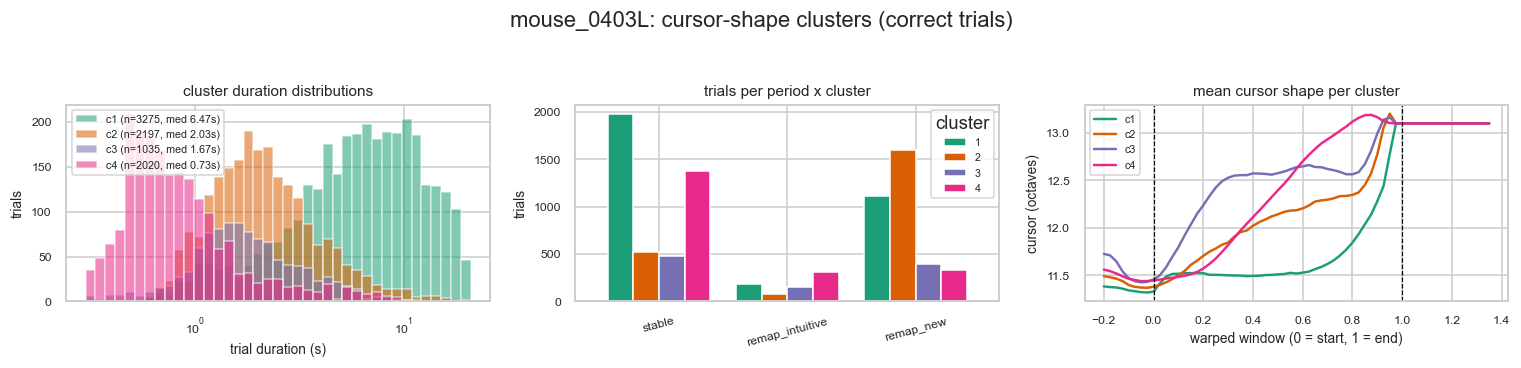

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for k in CLUSTERS:
    d = trials.loc[trials.cluster == k, "duration_sec"]
    axes[0].hist(d, bins=np.logspace(np.log10(0.3), np.log10(21), 40), alpha=0.55,
                 color=CLUSTER_COLORS[k], label=f"c{k} (n={len(d)}, med {d.median():.2f}s)")
axes[0].set(xscale="log", xlabel="trial duration (s)", ylabel="trials",
            title="cluster duration distributions")
axes[0].legend(fontsize=7)
cnt.plot(kind="bar", ax=axes[1], color=[CLUSTER_COLORS[k] for k in cnt.columns], width=0.8)
axes[1].set(ylabel="trials", xlabel="", title="trials per period x cluster")
axes[1].tick_params(axis="x", rotation=15); axes[1].legend(title="cluster", fontsize=7)
# mean cursor shape per cluster, for reference (the thing being clustered)
AX = ca.WindowSpec(pre_sec=PRE_SEC, post_sec=POST_SEC, n_trial_bins=N_TRIAL_BINS, sr=SR).axis()
for k in CLUSTERS:
    rows = M[trials.index[trials.cluster == k].to_numpy()]
    axes[2].plot(AX, rows.mean(0), color=CLUSTER_COLORS[k], lw=1.6, label=f"c{k}")
axes[2].axvline(0, color="k", ls="--", lw=0.8); axes[2].axvline(1, color="k", ls="--", lw=0.8)
axes[2].set(xlabel="warped window (0 = start, 1 = end)", ylabel="cursor (octaves)",
            title="mean cursor shape per cluster"); axes[2].legend(fontsize=7)
fig.suptitle(f"{MOUSE}: cursor-shape clusters ({OUTCOME} trials)", y=1.04)
show(fig, "S2_clusters_overview")

## 3 · Per-trial neural segments

One pass per day: load the population, z-score each neuron over the **whole session**, then cut out
`[trial start, effective trial end)` for every trial. Data stay at the native 30 Hz — the usual 6 Hz
binning is unusable here because the shortest cluster's trials are ~0.7 s, which a one-third window
would reduce to about two bins.

In [4]:
seg_fp = OUT / f"segments_{MOUSE}_{OUTCOME}_{TAG}.npz"
r = na.open_mouse(rfs, DATA_ROOT, MOUSE)
if USE_CACHE and seg_fp.exists():
    _z = np.load(seg_fp, allow_pickle=True)
    SEGS = {int(k): v for k, v in zip(_z["keys"], _z["vals"])}
else:
    t0 = time.time()
    SEGS = nc.extract_trial_neural(r, trials, progress=lambda x: tqdm(x, desc="days"))
    np.savez_compressed(seg_fp, keys=np.array(list(SEGS)),
                        vals=np.array(list(SEGS.values()), dtype=object))
    print(f"extracted in {time.time()-t0:.0f}s")
n_neu = next(iter(SEGS.values())).shape[1]
print(f"{len(SEGS)}/{len(trials)} trials with neural data | {n_neu} neurons | "
      f"{sum(v.nbytes for v in SEGS.values())/1e9:.2f} GB")

GROUPS = {(p, k): trials.index[(trials.period == p) & (trials.cluster == k)].to_numpy()
          for p in PERIODS for k in CLUSTERS}
N_TRIALS = int(min(64, nc.min_group_size(GROUPS, SEGS)))
print(f"smallest group = {nc.min_group_size(GROUPS, SEGS)} trials -> matched N_TRIALS = {N_TRIALS}"
      f"  (n_samples per PR estimate = {N_TRIALS * N_PER_TRIAL})")

8527/8527 trials with neural data | 468 neurons | 1.94 GB
smallest group = 79 trials -> matched N_TRIALS = 64  (n_samples per PR estimate = 256)


## 4 · Analysis 1 — participation ratio along the trial

`N_POSITIONS` overlapping windows slide from trial start to trial end. At each position, for each
(period, cluster): keep trials whose window holds at least `N_PER_TRIAL` frames, draw `N_TRIALS` of
them at random, draw `N_PER_TRIAL` frames from each, stack, and take the participation ratio of that
`(N_TRIALS × N_PER_TRIAL, n_neurons)` matrix. Repeat `N_BOOT` times; shaded bands are ±1 bootstrap SD.

Every estimate in every panel uses an identical sample budget, so sample-count and trial-count
biases cancel exactly. What does **not** cancel in `relative` mode is the window's real-time width,
which is printed per curve and plotted in the right-hand panel.

In [5]:
def run_pr(mode, width_frac=WIDTH_FRAC, width_sec=WIDTH_SEC, n_boot=N_BOOT, tag=""):
    cfg = nc.PRCurveConfig(n_positions=N_POSITIONS, mode=mode, width_frac=width_frac,
                           width_sec=width_sec, n_trials=N_TRIALS, n_per_trial=N_PER_TRIAL,
                           n_boot=n_boot, sr=SR, seed=SEED)
    fp = OUT / f"pr_{mode}{tag}_{N_TRIALS}x{N_PER_TRIAL}_{N_POSITIONS}pos.csv"
    if USE_CACHE and fp.exists():
        return pd.read_csv(fp), cfg
    t0 = time.time(); D = nc.pr_curves_by_group(SEGS, GROUPS, cfg)
    D.to_csv(fp, index=False); print(f"  {mode}{tag}: {time.time()-t0:.0f}s")
    return D, cfg

PR_REL, CFG_REL = run_pr("relative")
PR_ABS, CFG_ABS = run_pr("absolute")
print(f"relative: {PR_REL.pr.isna().sum()} missing cells | absolute: {PR_ABS.pr.isna().sum()} missing")
print("\nmean window duration (s) per group -- the residual confound in relative mode:")
display(PR_REL.groupby(["period", "cluster"]).win_sec.mean().unstack().reindex(PERIODS).round(2))

relative: 0 missing cells | absolute: 0 missing

mean window duration (s) per group -- the residual confound in relative mode:


cluster,1,2,3,4
period,,,,
stable,2.62,1.09,0.77,0.40
remap_intuitive,2.02,1.46,0.75,0.33
remap_new,2.27,0.78,0.60,0.31


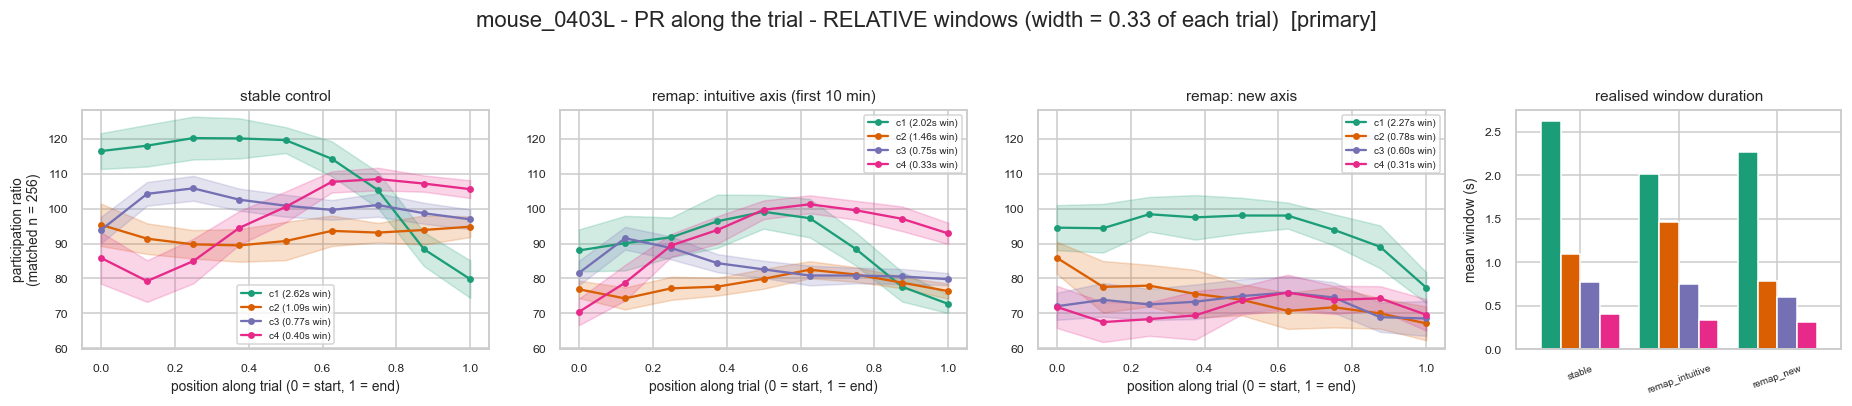

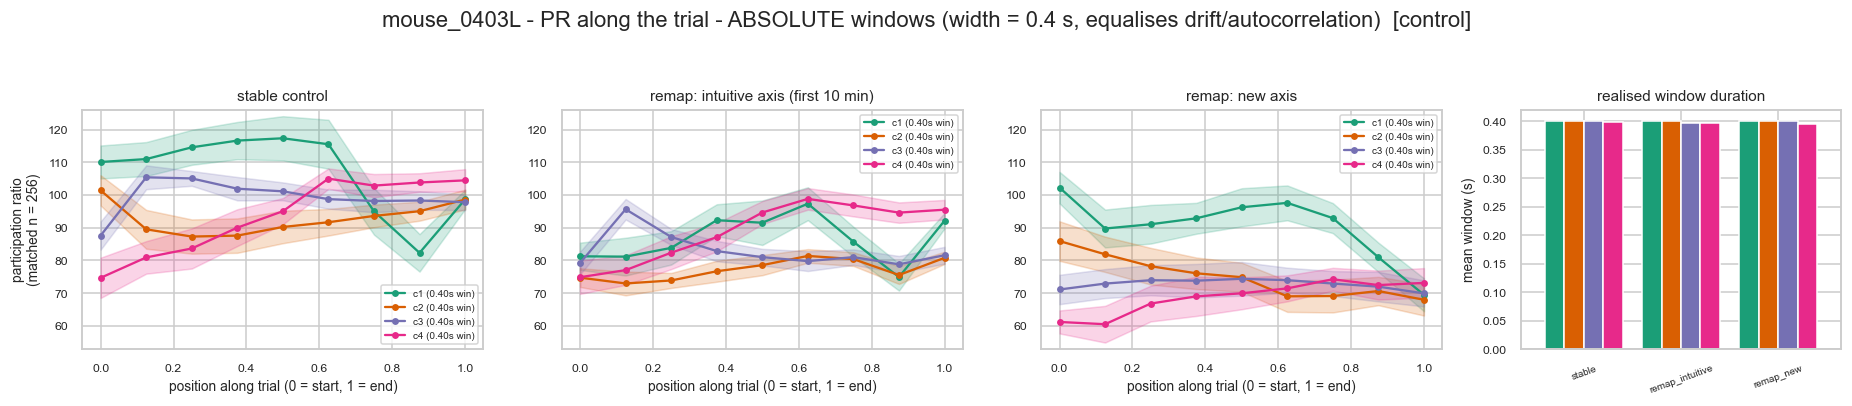

In [6]:
def plot_pr(D, title, fname, level="summary"):
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.5),
                             gridspec_kw=dict(width_ratios=[1, 1, 1, 0.8]))
    for ax, p in zip(axes[:3], PERIODS):
        for k in CLUSTERS:
            d = D[(D.period == p) & (D.cluster == k)].sort_values("position")
            if d.pr.isna().all(): continue
            x = d.rel_position
            ax.plot(x, d.pr, "-o", ms=3.5, color=CLUSTER_COLORS[k],
                    label=f"c{k} ({d.win_sec.mean():.2f}s win)")
            ax.fill_between(x, d.pr - d.pr_sd, d.pr + d.pr_sd, color=CLUSTER_COLORS[k], alpha=0.2)
        ax.set(title=PERIOD_LABEL[p], xlabel="position along trial (0 = start, 1 = end)")
        ax.legend(fontsize=6.5)
    axes[0].set_ylabel(f"participation ratio\n(matched n = {N_TRIALS * N_PER_TRIAL})")
    lo = np.nanmin(D.pr - D.pr_sd); hi = np.nanmax(D.pr + D.pr_sd)
    for ax in axes[:3]: ax.set_ylim(lo - 2, hi + 2)
    w = D.groupby(["period", "cluster"]).win_sec.mean().unstack().reindex(PERIODS)
    w.plot(kind="bar", ax=axes[3], color=[CLUSTER_COLORS[k] for k in w.columns], width=0.8,
           legend=False)
    axes[3].set(ylabel="mean window (s)", xlabel="", title="realised window duration")
    axes[3].tick_params(axis="x", rotation=20, labelsize=6.5)
    fig.suptitle(title, y=1.05)
    show(fig, fname, level)

plot_pr(PR_REL, f"{MOUSE} - PR along the trial - RELATIVE windows "
                f"(width = {WIDTH_FRAC:.2f} of each trial)  [primary]", "S4_pr_relative")
plot_pr(PR_ABS, f"{MOUSE} - PR along the trial - ABSOLUTE windows "
                f"(width = {WIDTH_SEC:g} s, equalises drift/autocorrelation)  [control]",
        "S4_pr_absolute")

Per-curve agreement between relative and absolute windows (overall r = 0.942):


,period,cluster,pearson_r,spearman_rho,mean_abs_diff
0,remap_intuitive,1,0.425,0.483,6.704
1,remap_intuitive,2,0.704,0.617,2.094
2,remap_intuitive,3,0.935,0.633,1.778
3,remap_intuitive,4,0.931,0.867,3.925
4,remap_new,1,0.880,0.550,4.843
5,remap_new,2,0.955,0.933,1.299
6,remap_new,3,0.790,0.817,1.378
7,remap_new,4,0.546,0.650,3.764
8,stable,1,0.822,0.750,6.795
9,stable,2,0.934,0.950,2.241


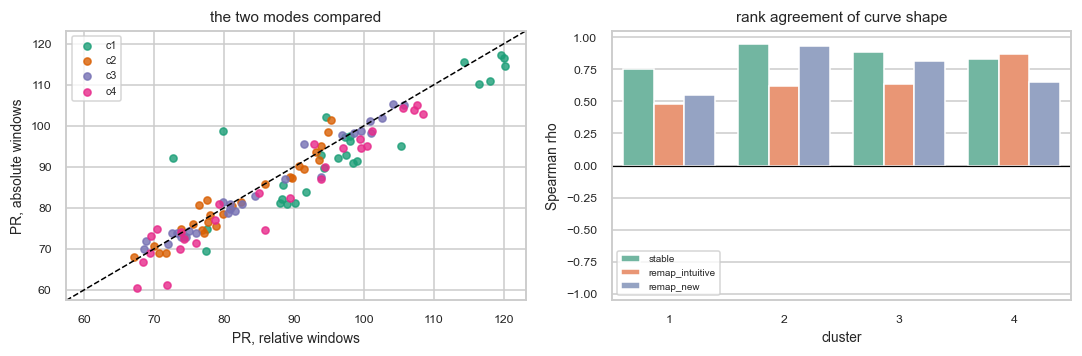

In [7]:
# Do the two window definitions agree? If they do, a difference is not a duration artefact.
mrg = PR_REL.merge(PR_ABS, on=["period", "cluster", "position"], suffixes=("_rel", "_abs"))
from scipy.stats import pearsonr, spearmanr
ok = mrg.pr_rel.notna() & mrg.pr_abs.notna()
rows = []
for (p, k), g in mrg[ok].groupby(["period", "cluster"]):
    if len(g) >= 4:
        rows.append(dict(period=p, cluster=k, pearson_r=pearsonr(g.pr_rel, g.pr_abs)[0],
                         spearman_rho=spearmanr(g.pr_rel, g.pr_abs).statistic,
                         mean_abs_diff=float(np.mean(np.abs(g.pr_rel - g.pr_abs)))))
agree = pd.DataFrame(rows)
print("Per-curve agreement between relative and absolute windows "
      f"(overall r = {pearsonr(mrg.pr_rel[ok], mrg.pr_abs[ok])[0]:.3f}):")
display(agree.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for k in CLUSTERS:
    g = mrg[ok & (mrg.cluster == k)]
    ax[0].scatter(g.pr_rel, g.pr_abs, s=22, color=CLUSTER_COLORS[k], label=f"c{k}", alpha=0.8)
lim = [min(mrg.pr_rel[ok].min(), mrg.pr_abs[ok].min()) - 3,
       max(mrg.pr_rel[ok].max(), mrg.pr_abs[ok].max()) + 3]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set(xlim=lim, ylim=lim, xlabel="PR, relative windows",
                                             ylabel="PR, absolute windows", title="the two modes compared")
ax[0].legend(fontsize=7)
sns.barplot(data=agree, x="cluster", y="spearman_rho", hue="period", ax=ax[1],
            palette="Set2", hue_order=PERIODS)
ax[1].set(ylim=(-1.05, 1.05), title="rank agreement of curve shape", ylabel="Spearman rho")
ax[1].axhline(0, color="k", lw=0.8); ax[1].legend(fontsize=6.5)
show(fig, "S4_mode_agreement")

### 4c · Sensitivity to the window width

The suggested width was ~1/5 of the trial; 1/3 is the default here. This re-runs the primary
(relative) analysis at each width in `WIDTH_SCAN`. Absolute PR values are **not** comparable between
widths — a wider window allows more frames per trial and a different sample budget — so what matters
is whether the **shape and ordering** of the curves survive.

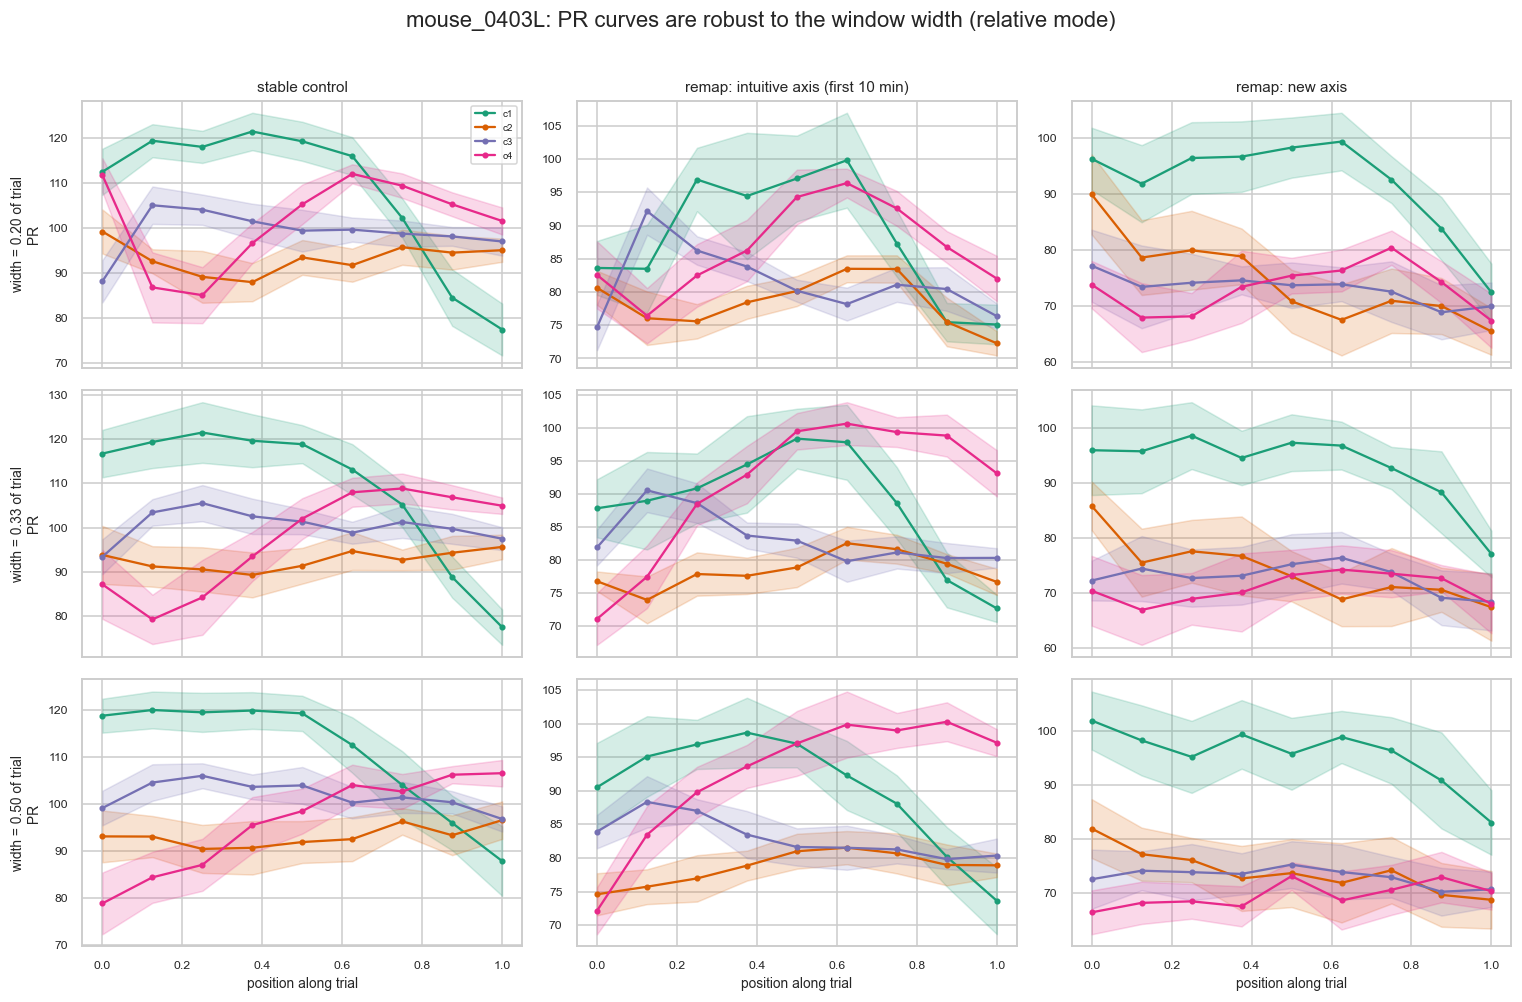

In [8]:
scan = {}
for wf in WIDTH_SCAN:
    D, _ = run_pr("relative", width_frac=wf, n_boot=max(10, N_BOOT // 2), tag=f"_w{wf:.2f}")
    scan[wf] = D
fig, axes = plt.subplots(len(WIDTH_SCAN), 3, figsize=(14, 3.0 * len(WIDTH_SCAN)),
                         squeeze=False, sharex=True)
for row, wf in enumerate(WIDTH_SCAN):
    D = scan[wf]
    for col, p in enumerate(PERIODS):
        ax = axes[row, col]
        for k in CLUSTERS:
            d = D[(D.period == p) & (D.cluster == k)].sort_values("position")
            if d.pr.isna().all(): continue
            ax.plot(d.rel_position, d.pr, "-o", ms=3, color=CLUSTER_COLORS[k], label=f"c{k}")
            ax.fill_between(d.rel_position, d.pr - d.pr_sd, d.pr + d.pr_sd,
                            color=CLUSTER_COLORS[k], alpha=0.18)
        if row == 0: ax.set_title(PERIOD_LABEL[p])
        if col == 0: ax.set_ylabel(f"width = {wf:.2f} of trial\nPR")
axes[0, 0].legend(fontsize=6.5)
for ax in axes[-1]: ax.set_xlabel("position along trial")
fig.suptitle(f"{MOUSE}: PR curves are robust to the window width (relative mode)", y=1.01)
show(fig, "S4c_width_sensitivity")

### 4d · Control at 6 Hz binning with 3 positions

Everything above runs on **native 30 Hz** data, because the shortest cursor-shape cluster has ~0.7 s
trials and the project's usual 6 Hz binning would leave a one-third window barely two bins wide.
That is the right choice for *this* question, but it makes the numbers awkward to line up against
the other neural notebooks, which all bin to 6 Hz.

So this section repeats Analysis 1 at **6 Hz (`BIN_FRAMES_CTRL = 5`) with only 3 window positions** —
the early, middle and late third of each trial. Binning is applied to the whole session **before**
z-scoring, matching `na.bin_and_zscore`, because z-scoring is a per-neuron rescaling and binning
changes each neuron's variance by a different amount; doing it in the other order would reweight
neurons in the covariance and therefore change PR.

**Read this as a coarse, comparable control — not as a replacement.** Three specific limits:

1. **Cluster 4's windows are forced to overlap.** A window of 1/3 of a 0.7 s trial is under two bins,
   and the implementation floors the width at 2 bins, so for a large share of cluster-4 trials the
   three "thirds" are not disjoint. The cell prints the affected fraction per cluster.
2. **The sample budget cannot match Section 4.** Cluster 4 can only supply 2 frames per window at
   6 Hz, and the smallest group caps the trial count, so this control runs at a *smaller* matched
   n than the main analysis. PR magnitudes are therefore **not** comparable between 4 and 4d —
   only the shape and the ordering of clusters are.
3. A handful of trials (<1 %) are too short to yield 2 bins and are dropped; the count is reported.

The last cell checks whether this coarse control reproduces the fine analysis, by averaging the
9-position 30 Hz curves into matching thirds and correlating the two.

In [9]:
seg6_fp = OUT / f"segments6hz_{MOUSE}_{OUTCOME}_{TAG}_b{BIN_FRAMES_CTRL}.npz"
if USE_CACHE and seg6_fp.exists():
    _z = np.load(seg6_fp, allow_pickle=True)
    SEGS6 = {int(k): v for k, v in zip(_z["keys"], _z["vals"])}
else:
    t0 = time.time()
    SEGS6 = nc.extract_trial_neural(r, trials, bin_frames=BIN_FRAMES_CTRL,
                                    min_frames=MIN_BINS_CTRL,
                                    progress=lambda x: tqdm(x, desc="days (6 Hz)"))
    np.savez_compressed(seg6_fp, keys=np.array(list(SEGS6)),
                        vals=np.array(list(SEGS6.values()), dtype=object))
    print(f"extracted in {time.time()-t0:.0f}s")
SR_CTRL = SR / BIN_FRAMES_CTRL
print(f"6 Hz segments: {len(SEGS6)}/{len(trials)} trials kept "
      f"({len(trials)-len(SEGS6)} dropped for having <{MIN_BINS_CTRL} bins) | "
      f"{sum(v.nbytes for v in SEGS6.values())/1e9:.2f} GB")

# How often is the 1/3 window floored at MIN_BINS_CTRL bins (i.e. the thirds stop being disjoint)?
rows = []
for k in CLUSTERS:
    ids = [i for i in trials.index[trials.cluster == k] if i in SEGS6]
    nb = np.array([SEGS6[i].shape[0] for i in ids])
    want = np.round(WIDTH_FRAC_CTRL * nb)
    rows.append(dict(cluster=k, n_trials=len(ids), median_bins=float(np.median(nb)),
                     median_window_bins=float(np.median(np.maximum(want, MIN_BINS_CTRL))),
                     frac_width_floored=float(np.mean(want < MIN_BINS_CTRL))))
FLOOR = pd.DataFrame(rows)
print("\nHow often the 1/3-of-trial window is floored at "
      f"{MIN_BINS_CTRL} bins (windows then overlap rather than tile):")
display(FLOOR.round(3))

GROUPS6 = {(p, k): np.array([i for i in trials.index[(trials.period == p) & (trials.cluster == k)]
                             if i in SEGS6]) for p in PERIODS for k in CLUSTERS}
N_TRIALS_CTRL = int(min(N_TRIALS, nc.min_group_size(GROUPS6, SEGS6)))
print(f"smallest group = {nc.min_group_size(GROUPS6, SEGS6)} -> matched N_TRIALS = {N_TRIALS_CTRL}"
      f"  (n_samples = {N_TRIALS_CTRL * N_PER_TRIAL_CTRL}; Section 4 used {N_TRIALS * N_PER_TRIAL})")

days (6 Hz):   0%|          | 0/35 [00:00<?, ?it/s]

extracted in 30s
6 Hz segments: 8524/8527 trials kept (3 dropped for having <2 bins) | 0.39 GB

How often the 1/3-of-trial window is floored at 2 bins (windows then overlap rather than tile):


,cluster,n_trials,median_bins,median_window_bins,frac_width_floored
0,1,3275,39.0,13.0,0.005
1,2,2197,12.0,4.0,0.016
2,3,1035,10.0,3.0,0.072
3,4,2017,4.0,2.0,0.518


smallest group = 79 -> matched N_TRIALS = 64  (n_samples = 128; Section 4 used 256)


6 Hz PR curves in 1s
missing cells: 0

Participation ratio at 6 Hz, matched n = 128:


early  middle  late
period          cluster                     
stable          1         52.2    56.4  27.5
                2         39.4    37.5  43.7
                3         32.5    49.3  48.1
                4         30.1    32.4  49.4
remap_intuitive 1         32.1    40.2  24.7
                2         27.9    32.8  33.9
                3         23.5    34.8  36.1
                4         19.9    27.4  41.3
remap_new       1         38.9    40.1  31.8
                2         34.3    32.5  32.1
                3         25.0    32.8  33.2
                4         24.1    24.6  29.6

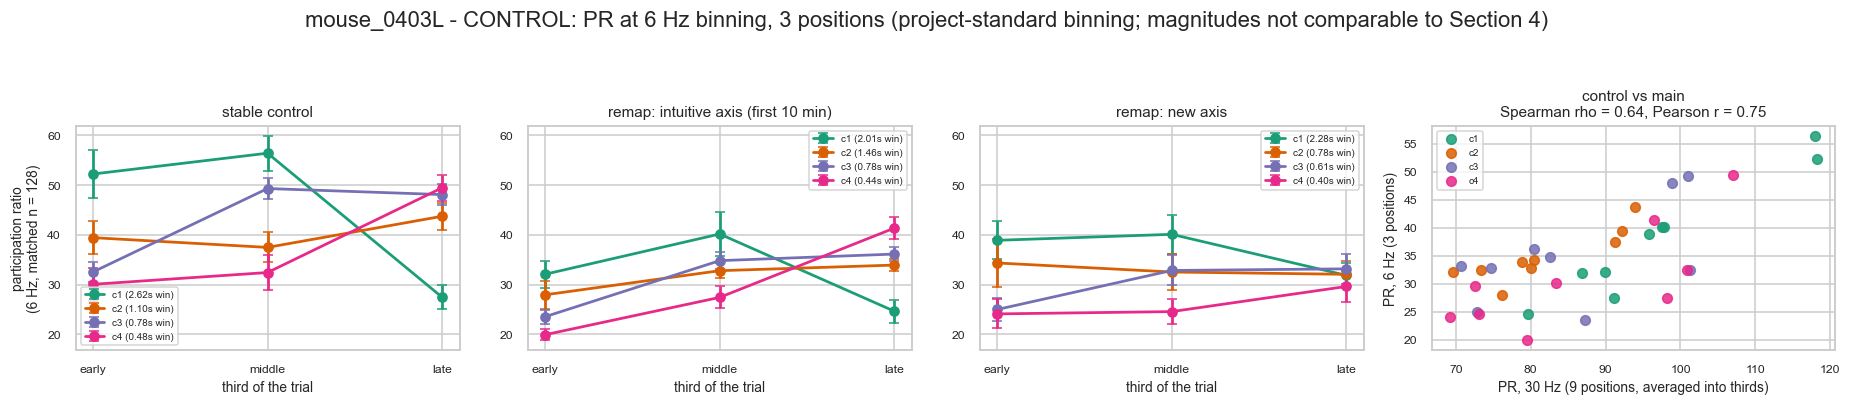

Agreement between the 6 Hz/3-point control and the 30 Hz/9-point analysis: Spearman rho = 0.638, Pearson r = 0.747 over 36 cells.
Per-cluster rank agreement:


,cluster,spearman
0,1,0.917
1,2,0.933
2,3,0.250
3,4,0.717


In [10]:
cfg6 = nc.PRCurveConfig(n_positions=N_POSITIONS_CTRL, mode="relative",
                        width_frac=WIDTH_FRAC_CTRL, n_trials=N_TRIALS_CTRL,
                        n_per_trial=N_PER_TRIAL_CTRL, n_boot=N_BOOT, sr=SR_CTRL, seed=SEED)
fp6 = OUT / f"pr_6hz_{N_TRIALS_CTRL}x{N_PER_TRIAL_CTRL}_{N_POSITIONS_CTRL}pos.csv"
if USE_CACHE and fp6.exists():
    PR6 = pd.read_csv(fp6)
else:
    t0 = time.time(); PR6 = nc.pr_curves_by_group(SEGS6, GROUPS6, cfg6)
    PR6.to_csv(fp6, index=False); print(f"6 Hz PR curves in {time.time()-t0:.0f}s")
print(f"missing cells: {int(PR6.pr.isna().sum())}")
THIRDS = ["early", "middle", "late"]
tab = PR6.pivot_table(index=["period", "cluster"], columns="position", values="pr").reindex(PERIODS, level=0)
tab.columns = THIRDS
print(f"\nParticipation ratio at 6 Hz, matched n = {N_TRIALS_CTRL * N_PER_TRIAL_CTRL}:")
display(tab.round(1))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.5), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.05]))
x = np.arange(N_POSITIONS_CTRL)
for ax, p in zip(axes[:3], PERIODS):
    for k in CLUSTERS:
        d = PR6[(PR6.period == p) & (PR6.cluster == k)].sort_values("position")
        if d.pr.isna().all(): continue
        ax.errorbar(x, d.pr, yerr=d.pr_sd, marker="o", ms=6, capsize=3, lw=1.8,
                    color=CLUSTER_COLORS[k], label=f"c{k} ({d.win_sec.mean():.2f}s win)")
    ax.set(title=PERIOD_LABEL[p], xticks=x, xlabel="third of the trial")
    ax.set_xticklabels(THIRDS); ax.legend(fontsize=6.5)
axes[0].set_ylabel(f"participation ratio\n(6 Hz, matched n = {N_TRIALS_CTRL * N_PER_TRIAL_CTRL})")
lo, hi = np.nanmin(PR6.pr - PR6.pr_sd), np.nanmax(PR6.pr + PR6.pr_sd)
for ax in axes[:3]: ax.set_ylim(lo - 2, hi + 2)

# does the coarse 6 Hz control reproduce the fine 30 Hz analysis?
third_of = {p: p * N_POSITIONS_CTRL // N_POSITIONS for p in range(N_POSITIONS)}
fine = (PR_REL.assign(third=PR_REL.position.map(third_of))
        .groupby(["period", "cluster", "third"], as_index=False).pr.mean()
        .rename(columns={"pr": "pr_30hz"}))
comp = fine.merge(PR6.rename(columns={"position": "third", "pr": "pr_6hz"})[
    ["period", "cluster", "third", "pr_6hz"]], on=["period", "cluster", "third"])
ok = comp.pr_30hz.notna() & comp.pr_6hz.notna()
rho = spearmanr(comp.pr_30hz[ok], comp.pr_6hz[ok]).statistic
rp = pearsonr(comp.pr_30hz[ok], comp.pr_6hz[ok])[0]
for k in CLUSTERS:
    g = comp[ok & (comp.cluster == k)]
    axes[3].scatter(g.pr_30hz, g.pr_6hz, s=40, color=CLUSTER_COLORS[k], label=f"c{k}", alpha=0.85)
axes[3].set(xlabel="PR, 30 Hz (9 positions, averaged into thirds)", ylabel="PR, 6 Hz (3 positions)",
            title=f"control vs main\nSpearman rho = {rho:.2f}, Pearson r = {rp:.2f}")
axes[3].legend(fontsize=6.5)
fig.suptitle(f"{MOUSE} - CONTROL: PR at {SR_CTRL:.0f} Hz binning, 3 positions "
             f"(project-standard binning; magnitudes not comparable to Section 4)", y=1.05)
show(fig, "S4d_pr_6hz_3pos")

print(f"Agreement between the 6 Hz/3-point control and the 30 Hz/9-point analysis: "
      f"Spearman rho = {rho:.3f}, Pearson r = {rp:.3f} over {int(ok.sum())} cells.")
print("Per-cluster rank agreement:")
display(pd.DataFrame([dict(cluster=k,
                           spearman=spearmanr(comp.pr_30hz[ok & (comp.cluster == k)],
                                              comp.pr_6hz[ok & (comp.cluster == k)]).statistic)
                      for k in CLUSTERS]).round(3))

## 5 · Analysis 2 — average neural trajectory per cluster in PC space

One PC basis is fitted for the animal on frames sampled **equally from every (period, cluster)
group**, so that (a) all twelve groups live in the same coordinate system and the panels are
directly comparable, and (b) the largest group — always the longest-trial cluster — cannot define
the axes by itself.

Each trial is projected into that basis and **linearly time-warped** to `N_WARP` points spanning
trial start to trial end, then averaged within a group. This is the same warping the cursor-shape
analysis uses, so "position along the trial" means the same thing in both notebooks. Since the
clusters differ systematically in duration, these are trajectories through **relative** trial time,
not real time.

Shown as **PC pairs** rather than a 3-D projection, with **axis limits shared across the three
period panels** — because the basis is shared, where a trajectory sits is as informative as its
shape, and per-panel autoscaling would hide it.

In [11]:
pca_fp = OUT / f"pca_{MOUSE}_{OUTCOME}_k{N_PC}.npz"
if USE_CACHE and pca_fp.exists():
    _z = np.load(pca_fp)
    SUB = na.Subspace(_z["components"], _z["mean"], _z["explained_ratio"])
else:
    t0 = time.time()
    SUB = nc.fit_pca_balanced(SEGS, GROUPS, k=N_PC, n_per_group=PCA_MAX_FRAMES_PER_GROUP, seed=SEED)
    np.savez(pca_fp, components=SUB.components, mean=SUB.mean, explained_ratio=SUB.explained_ratio)
    print(f"PCA fitted in {time.time()-t0:.0f}s")
print(f"shared {N_PC}-PC basis | variance explained per PC: {np.round(SUB.explained_ratio, 4)}"
      f" (cumulative {SUB.explained_ratio.sum():.3f})")
TRAJ = nc.trajectory_table(SEGS, GROUPS, SUB, n_warp=N_WARP, seed=SEED)
print("trials averaged per group:", {f"{p[:5]}-c{k}": TRAJ[(p, k)][2] for p, k in TRAJ})

shared 6-PC basis | variance explained per PC: [0.0742 0.0178 0.0155 0.0109 0.009  0.0085] (cumulative 0.136)


trials averaged per group: {'stabl-c1': 1980, 'stabl-c2': 521, 'stabl-c3': 482, 'stabl-c4': 1379, 'remap-c1': 1111, 'remap-c2': 1597, 'remap-c3': 395, 'remap-c4': 330}


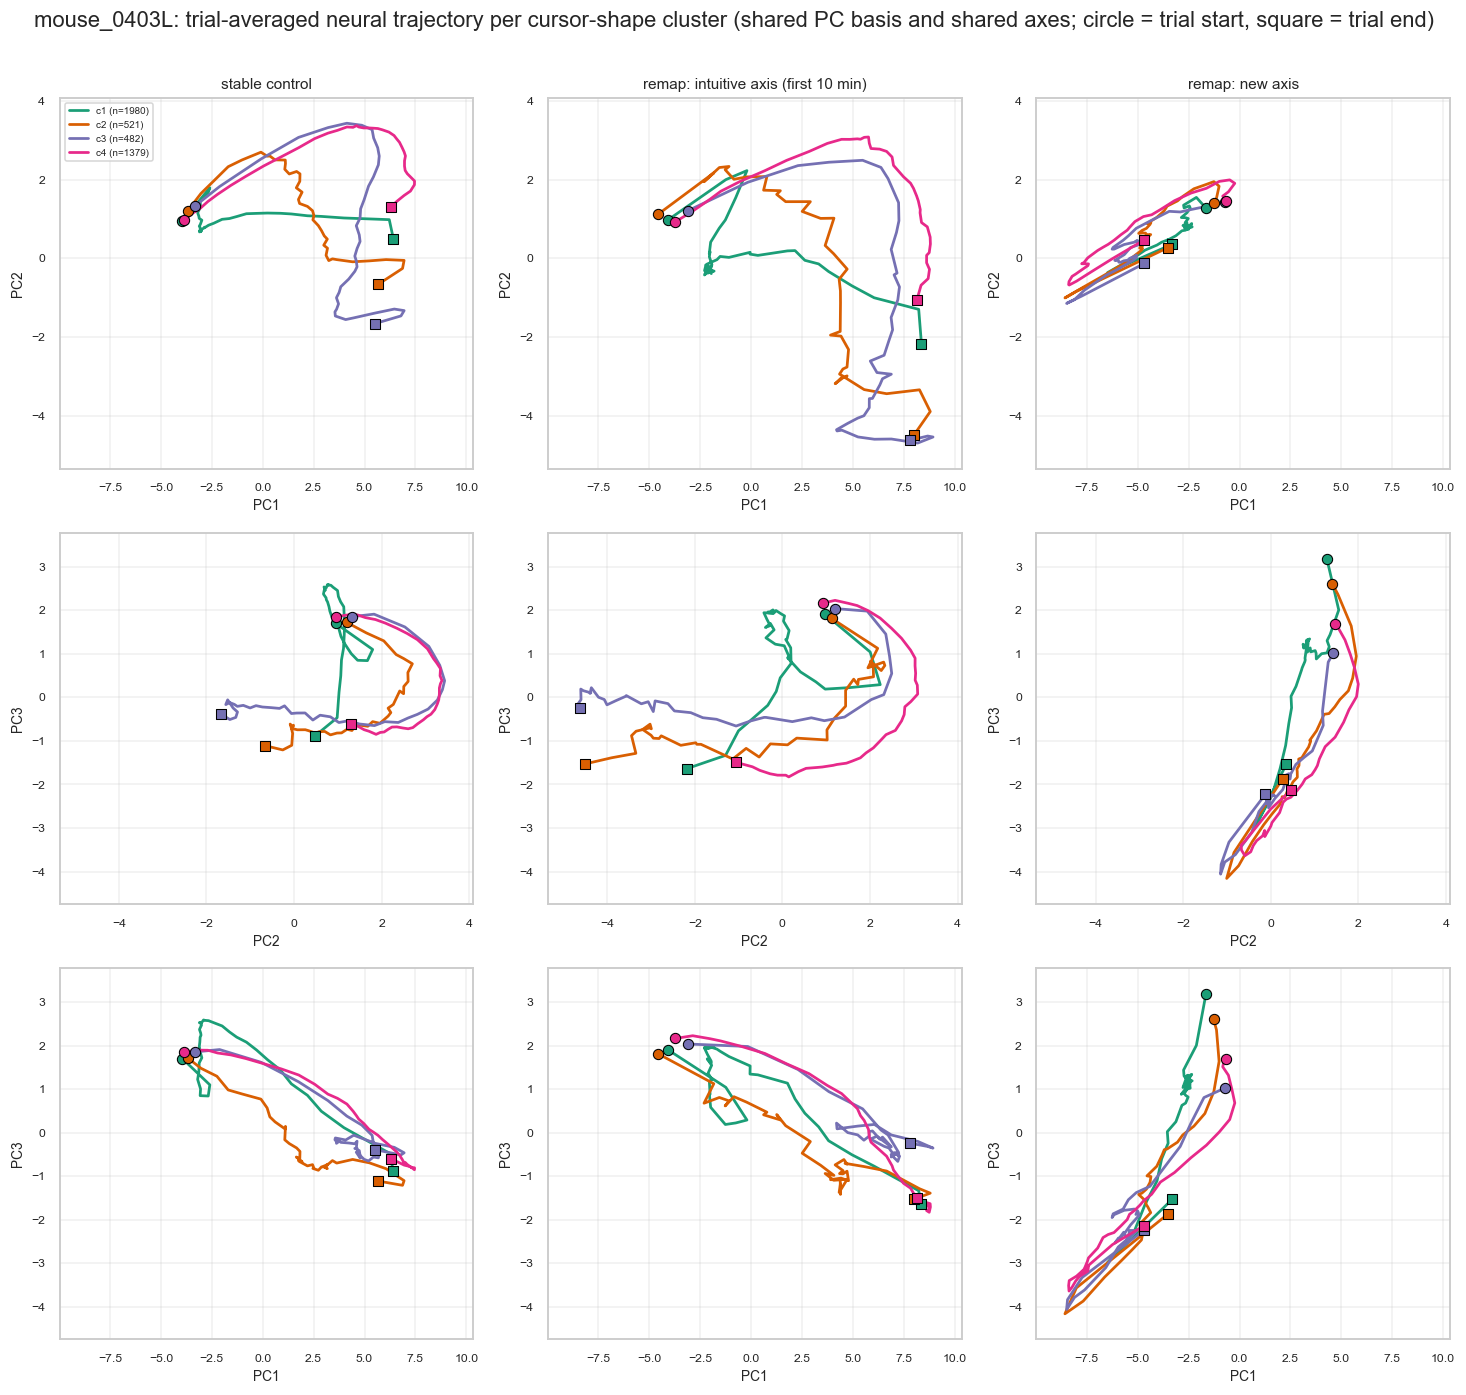

In [12]:
PC_PAIRS = [(0, 1), (1, 2), (0, 2)]
# All panels share one PC basis, so the coordinate RANGES are themselves meaningful: letting each
# panel autoscale would hide the fact that different periods occupy different regions of the space.
# Limits are therefore shared across the three period panels of a row.
_all = np.vstack([m for m, _, n_ in TRAJ.values() if n_])
_lim = [(_all[:, j].min(), _all[:, j].max()) for j in range(N_PC)]
def _pad(lo, hi, f=0.08):
    m = (hi - lo) * f or 1.0
    return lo - m, hi + m
fig, axes = plt.subplots(len(PC_PAIRS), 3, figsize=(13.5, 4.2 * len(PC_PAIRS)), squeeze=False)
for row, (a, b) in enumerate(PC_PAIRS):
    for col, p in enumerate(PERIODS):
        ax = axes[row, col]
        for k in CLUSTERS:
            m, se, n = TRAJ[(p, k)]
            if n == 0: continue
            ax.plot(m[:, a], m[:, b], "-", color=CLUSTER_COLORS[k], lw=1.8,
                    label=f"c{k} (n={n})")
            ax.scatter(*m[0, [a, b]], color=CLUSTER_COLORS[k], marker="o", s=45,
                       edgecolor="k", zorder=5, linewidths=0.7)
            ax.scatter(*m[-1, [a, b]], color=CLUSTER_COLORS[k], marker="s", s=45,
                       edgecolor="k", zorder=5, linewidths=0.7)
        ax.set(xlabel=f"PC{a+1}", ylabel=f"PC{b+1}",
               xlim=_pad(*_lim[a]), ylim=_pad(*_lim[b]))
        if row == 0: ax.set_title(PERIOD_LABEL[p])
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=6.5)
fig.suptitle(f"{MOUSE}: trial-averaged neural trajectory per cursor-shape cluster "
             f"(shared PC basis and shared axes; circle = trial start, square = trial end)",
             y=1.005)
show(fig, "S5_trajectories_pcpairs")

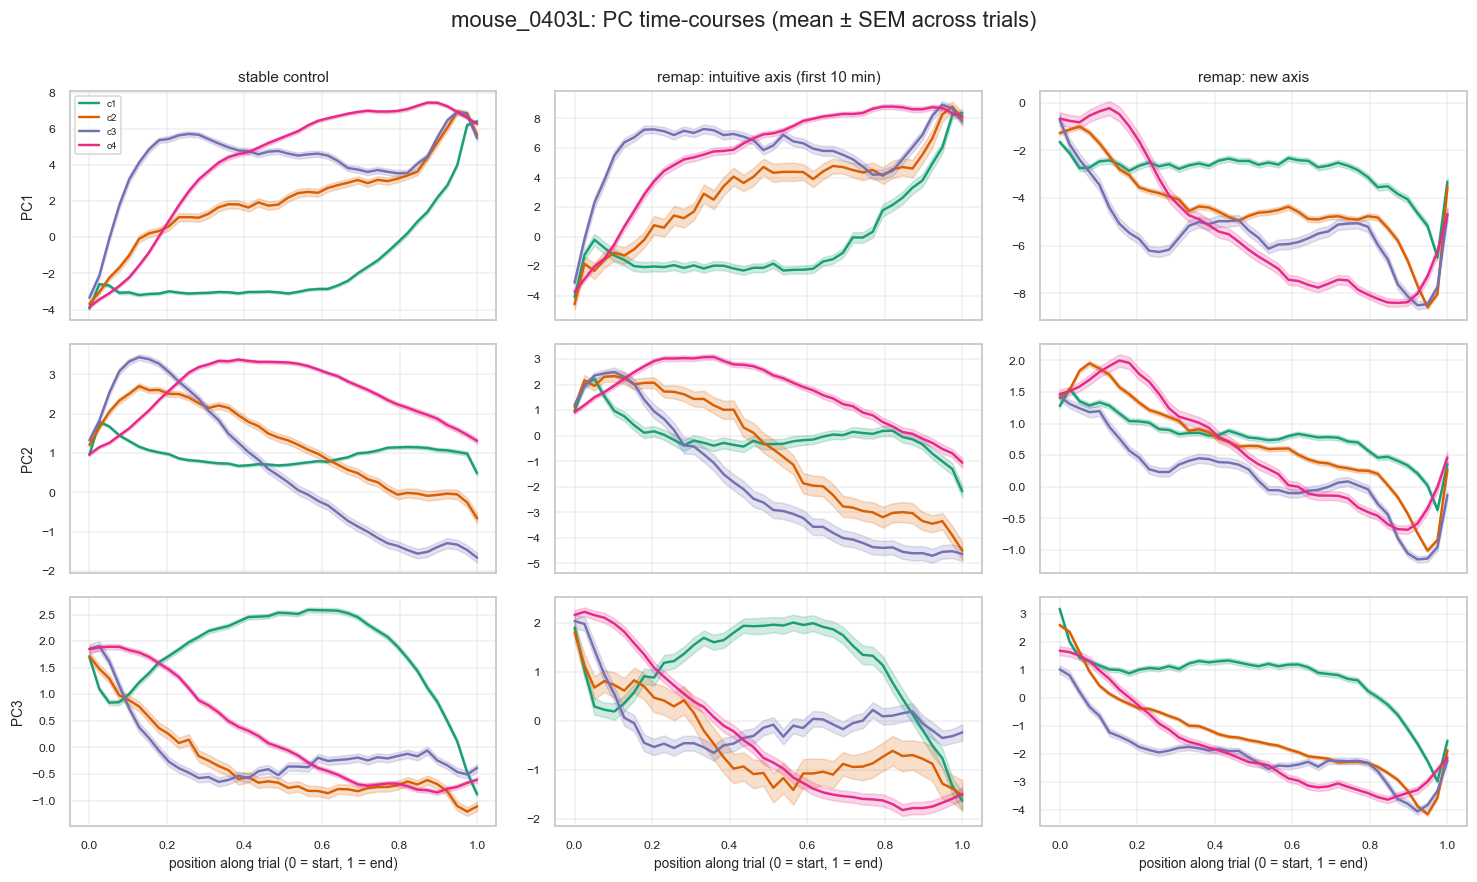

Geometry of the trial-averaged trajectories (in the shared PC basis):


net_displacement                      path_length         \
cluster                        1      2      3      4           1      2   
period                                                                     
stable                     10.79  10.09   9.80  10.53       15.84  17.71   
remap_intuitive            13.36  14.21  12.65  12.79       25.87  30.58   
remap_new                   5.65   5.90   5.86   5.81       17.47  21.40   

                               
cluster              3      4  
period                         
stable           22.65  14.90  
remap_intuitive  30.53  18.33  
remap_new        22.78  18.18

In [13]:
# PC time-courses, which make the timing of each cluster's excursion readable
fig, axes = plt.subplots(3, 3, figsize=(13.5, 8.0), sharex=True)
tt = np.linspace(0, 1, N_WARP)
for row in range(3):
    for col, p in enumerate(PERIODS):
        ax = axes[row, col]
        for k in CLUSTERS:
            m, se, n = TRAJ[(p, k)]
            if n == 0: continue
            ax.plot(tt, m[:, row], color=CLUSTER_COLORS[k], lw=1.6, label=f"c{k}")
            ax.fill_between(tt, m[:, row] - se[:, row], m[:, row] + se[:, row],
                            color=CLUSTER_COLORS[k], alpha=0.2)
        if row == 0: ax.set_title(PERIOD_LABEL[p])
        if col == 0: ax.set_ylabel(f"PC{row+1}")
        ax.grid(alpha=0.3)
for ax in axes[-1]: ax.set_xlabel("position along trial (0 = start, 1 = end)")
axes[0, 0].legend(fontsize=6.5)
fig.suptitle(f"{MOUSE}: PC time-courses (mean ± SEM across trials)", y=1.0)
show(fig, "S5_pc_timecourses")

# how far the trajectory travels, and how far it ends from where it began
rows = []
for (p, k), (m, se, n) in TRAJ.items():
    if n == 0: continue
    rows.append(dict(period=p, cluster=k, n=n, path_length=na.trajectory_length(m),
                     net_displacement=float(np.linalg.norm(m[-1] - m[0])),
                     radius_of_gyration=float(np.sqrt(np.sum(m.var(axis=0))))))
GEO = pd.DataFrame(rows)
print("Geometry of the trial-averaged trajectories (in the shared PC basis):")
display(GEO.pivot_table(index="period", columns="cluster",
                        values=["path_length", "net_displacement"]).reindex(PERIODS).round(2))

## 6 · Correctness checks and caveats

In [14]:
checks = []
def chk(name, ok, detail=""):
    checks.append(dict(check=name, result="PASS" if ok else "FAIL", detail=detail))

chk("cursor clusters reproduce Section 7 exactly", sizes == EXPECTED_SIZES, f"{sizes}")
chk("washout excluded from every group",
    not any("washout" in str(v) for v in trials.block.unique() if trials.period.notna().all()) or
    (trials.block != "washout").all(), f"blocks kept: {sorted(trials.block.unique())}")
chk("every analysed trial has neural data", len(SEGS) == len(trials), f"{len(SEGS)}/{len(trials)}")
chk("segment lengths equal trial durations",
    bool(np.allclose([SEGS[i].shape[0] for i in trials.index[:500]],
                     (trials.duration_sec[:500] * SR).round(), atol=1.01)))
chk("matched sample budget identical in every PR cell",
    PR_REL.n_available.min() >= N_TRIALS, f"smallest available pool = {PR_REL.n_available.min()}")
chk("no missing PR cells (relative)", int(PR_REL.pr.isna().sum()) == 0)
chk("no missing PR cells (absolute)", int(PR_ABS.pr.isna().sum()) == 0)
chk("absolute mode really equalises window duration",
    float(PR_ABS.groupby(["period", "cluster"]).win_sec.mean().std()) < 0.05,
    f"sd across groups = {PR_ABS.groupby(['period','cluster']).win_sec.mean().std():.4f}s")
chk("relative mode window duration does vary (as expected)",
    float(PR_REL.groupby(["period", "cluster"]).win_sec.mean().std()) > 0.2,
    f"sd across groups = {PR_REL.groupby(['period','cluster']).win_sec.mean().std():.3f}s")
chk("fast PR matches the reference implementation",
    bool(np.isclose(nc.participation_ratio(np.vstack([SEGS[i][:4] for i in list(SEGS)[:70]]).astype(float)),
                    na.pca_spectrum(np.vstack([SEGS[i][:4] for i in list(SEGS)[:70]]).astype(float)).participation_ratio)))
chk("6 Hz control kept >=99% of trials", len(SEGS6) / len(trials) > 0.99,
    f"{len(SEGS6)}/{len(trials)}")
chk("6 Hz control has no missing PR cells", int(PR6.pr.isna().sum()) == 0)
chk("6 Hz segments are ~5x shorter than 30 Hz ones",
    bool(abs(np.median([SEGS[i].shape[0] / SEGS6[i].shape[0] for i in list(SEGS6)[:300]])
             - BIN_FRAMES_CTRL) < 0.35))
chk("control reproduces the main analysis ordering", rho > 0.5, f"Spearman rho = {rho:.3f}")
chk("PC basis is shared across all panels", SUB.components.shape == (N_PC, n_neu))
chk("trajectories are finite", all(np.isfinite(m).all() for m, _, n in TRAJ.values() if n))
display(pd.DataFrame(checks))

print('''
Caveats:
 1. Absolute PR values are biased downward by the matched sample budget (n = {n}) and are only
    comparable WITHIN one setting of (n_trials, n_per_trial, mode, width). Compare shapes and
    ordering between clusters, never raw magnitudes across settings or against other notebooks.
 2. The clusters are largely duration clusters (~9x median spread, barely overlapping
    distributions), so they cannot be duration-matched without discarding almost all trials.
    The relative/absolute pair brackets that confound rather than removing it.
 3. In relative mode the window spans different real durations per cluster (reported on every
    curve); in absolute mode it spans a different fraction of the trial. Neither is confound-free.
 4. Time-warping equates a fast and a slow trial that differ only in speed, so the trajectories
    are through relative trial time. Real durations are in the table in Section 2.
 5. Trials are pooled across days within a period. Neurons are tracked across days, but slow
    across-day drift still adds variance; the clusters are spread over essentially all days
    (checked in the cursor-shape notebook), so this affects them similarly but not identically.
 6. PR is computed on native 30 Hz data, which is temporally autocorrelated. That depresses PR
    overall and does so more in short windows -- another reason to read the absolute-mode control.
 7. Only correct trials of one animal are analysed here, because the Section-7 clusters are
    defined for correct trials and only mouse_0403L has both phases.
 8. The 6 Hz control (Section 4d) runs at a smaller matched sample budget than Section 4, so its
    PR MAGNITUDES are not comparable with Section 4 -- only shapes and cluster ordering are. It
    also floors cluster 4's window at 2 bins, so for a large share of cluster-4 trials the three
    "thirds" overlap instead of tiling; the exact fraction is printed in that section.
'''.format(n=N_TRIALS * N_PER_TRIAL))

,check,result,detail
0,cursor clusters reproduce Section 7 exactly,PASS,"[np.int64(3520), np.int64(2263), np.int64(1164..."
1,washout excluded from every group,PASS,"blocks kept: ['intuitive_pre', 'new', 'single']"
2,every analysed trial has neural data,PASS,8527/8527
3,segment lengths equal trial durations,PASS,
4,matched sample budget identical in every PR cell,PASS,smallest available pool = 79
5,no missing PR cells (relative),PASS,
6,no missing PR cells (absolute),PASS,
7,absolute mode really equalises window duration,PASS,sd across groups = 0.0016s
8,relative mode window duration does vary (as ex...,PASS,sd across groups = 0.794s
9,fast PR matches the reference implementation,PASS,



Caveats:
 1. Absolute PR values are biased downward by the matched sample budget (n = 256) and are only
    comparable WITHIN one setting of (n_trials, n_per_trial, mode, width). Compare shapes and
    ordering between clusters, never raw magnitudes across settings or against other notebooks.
 2. The clusters are largely duration clusters (~9x median spread, barely overlapping
    distributions), so they cannot be duration-matched without discarding almost all trials.
    The relative/absolute pair brackets that confound rather than removing it.
 3. In relative mode the window spans different real durations per cluster (reported on every
    curve); in absolute mode it spans a different fraction of the trial. Neither is confound-free.
 4. Time-warping equates a fast and a slow trial that differ only in speed, so the trajectories
    are through relative trial time. Real durations are in the table in Section 2.
 5. Trials are pooled across days within a period. Neurons are tracked acro